# Subject-level prior effect against tremor dominance

Continuous counterpart of the subject-level part of `notebooks/2.20-psych-model-fitting-color`. That
notebook computed each session's prior effect (Positive-Prior minus Equal-Prior psychometric
parameter) and then compared OFF, ON and the OFF-to-ON change (the difference-in-differences, DiD)
within the tremor-dominant and bradykinesia-dominant groups. Here the same per-patient numbers are
correlated with the continuous score from `1.10-tremor-brady-score`, across all 22 patients who have it.

| Categorical question (`notebooks/2.20`) | Continuous question (here) |
|---|---|
| Is the prior effect non-zero OFF / ON within each subtype? | Does the OFF / ON prior effect vary with tremor dominance? |
| Is the DiD non-zero within each subtype? | Does the DiD vary with tremor dominance? |
| Do the subtypes' DiDs differ (Mann-Whitney)? | Same question, as a correlation with every patient's actual score |

**Primary test, fixed in advance:** Spearman correlation between the score and the DiD of `bias`
(the proportion of positive choices at 0% coherence), the quantity the categorical analysis was
built around. The `psych_alpha` and `psych_beta` rows, and the OFF and ON rows, are secondary and
are given with a Holm correction across all of them.

`bias` here is identical, to machine precision, to the model-free 0%-coherence prior effect in
`notebooks/2.28` (checked during development), so it is reported once.

p-values are from 20,000 permutations; intervals are percentile bootstraps over patients.

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *

In [2]:
from statsmodels.stats.multitest import multipletests

from config import dir_config
from src.utils.motor_score import OUTPUT_DIR, SCORE, correlate, leave_one_out_rho, motor_scores

processed_dir = Path(dir_config.data.processed)
metadata = pd.read_csv(processed_dir / "processed_metadata_all_data_accu_60.csv", encoding="latin1")
assert not str(OUTPUT_DIR).startswith(str(processed_dir.parents[0])), "never write to the data dir"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

scores = motor_scores(metadata)
CATEGORY_COLOR = {"tremor": "#B5541D", "bradykinetic": "#4A5A6B", "intermediate": "#9A9A9A"}
PARAMS = {"bias": "bias (P(positive) at 0% coh.)", "psych_alpha": "threshold (alpha)", "psych_beta": "slope (beta)"}

## Per-patient prior effects

Prior effect = Positive-Prior minus Equal-Prior value of each psychometric parameter, per session.
DiD = ON minus OFF prior effect, per patient.

In [3]:
sessions = metadata[metadata["subject_id"].isin(scores.index) & metadata["treatment"].isin(["OFF", "ON"])]
frames = {}
for param in PARAMS:
    effect = (sessions[f"positive_{param}"] - sessions[f"equal_{param}"]).to_numpy()
    wide = pd.DataFrame({"subject_id": sessions["subject_id"].to_numpy(), "state": sessions["treatment"].to_numpy(), "effect": effect}).pivot(index="subject_id", columns="state", values="effect")
    wide["DiD"] = wide["ON"] - wide["OFF"]
    frames[param] = wide.reindex(scores.index)

prior_effects = pd.concat(frames, axis=1)
prior_effects.columns = [f"{param} {state}" for param, state in prior_effects.columns]
assert prior_effects.notna().all().all()
prior_effects.join(scores[[SCORE, "category"]]).round(3)

,bias OFF,bias ON,bias DiD,psych_alpha OFF,psych_alpha ON,psych_alpha DiD,psych_beta OFF,psych_beta ON,psych_beta DiD,log2_trem_by_brady,category
subject_id,,,,,,,,,,,
P22,0.162,-0.188,-0.350,-29.895,18.894,48.789,-0.002,-0.030,-0.028,-3.366,bradykinetic
P23,0.443,0.102,-0.341,-67.618,-23.594,44.024,-0.030,0.006,0.036,-2.707,bradykinetic
P1,-0.020,0.324,0.343,1.753,-17.859,-19.612,-0.010,0.022,0.032,-2.353,bradykinetic
P33,0.132,0.070,-0.062,2.233,-24.576,-26.809,-0.015,0.027,0.042,-2.044,bradykinetic
P20,-0.012,0.132,0.144,7.099,-10.148,-17.247,0.011,-0.006,-0.017,-1.510,bradykinetic
P28,0.034,0.177,0.143,-4.655,-21.502,-16.847,0.005,0.023,0.018,-1.267,bradykinetic
P13,0.026,-0.056,-0.082,17.433,4.316,-13.118,0.002,-0.016,-0.018,-1.196,bradykinetic
P9,-0.087,-0.043,0.045,19.618,2.582,-17.036,-0.000,0.019,0.020,-0.781,bradykinetic
P34,-0.051,0.050,0.101,0.368,3.547,3.179,0.010,-0.020,-0.030,-0.459,bradykinetic


## Correlations with the score

In [4]:
rows = []
for param in PARAMS:
    for state in ["OFF", "ON", "DiD"]:
        result = correlate(scores[SCORE], prior_effects[f"{param} {state}"])
        rows.append({"parameter": param, "prior effect": state, **result})

correlations = pd.DataFrame(rows).set_index(["parameter", "prior effect"])
primary = ("bias", "DiD")
secondary = [i for i in correlations.index if i != primary]
correlations["Holm p (secondary)"] = np.nan
correlations.loc[secondary, "Holm p (secondary)"] = multipletests(correlations.loc[secondary, "p (perm, rho)"], method="holm")[1]
correlations.round(3)

n  spearman rho  rho 2.5%  rho 97.5%  \
parameter   prior effect                                          
bias        OFF           22        -0.248    -0.632      0.207   
            ON            22         0.042    -0.425      0.485   
            DiD           22         0.209    -0.305      0.604   
psych_alpha OFF           22         0.132    -0.349      0.559   
            ON            22         0.126    -0.326      0.532   
            DiD           22        -0.034    -0.491      0.441   
psych_beta  OFF           22        -0.047    -0.500      0.422   
            ON            22        -0.076    -0.568      0.407   
            DiD           22        -0.136    -0.613      0.351   

                          p (perm, rho)  pearson r  p (perm, r)  \
parameter   prior effect                                          
bias        OFF                   0.265     -0.155        0.485   
            ON                    0.853      0.085        0.712   
            DiD                   0.348      0.165        0.468   
psych_alpha OFF                   0.560      0.269        0.225   
            ON                    0.572      0.011        0.962   
            DiD                   0.877     -0.224        0.317   
psych_beta  OFF                   0.838     -0.057        0.801   
            ON                    0.737      0.034        0.884   
            DiD                   0.542      0.056        0.809   

                          Holm p (secondary)  
parameter   prior effect                      
bias        OFF                          1.0  
            ON                           1.0  
            DiD                          NaN  
psych_alpha OFF                          1.0  
            ON                           1.0  
            DiD                          1.0  
psych_beta  OFF                          1.0  
            ON                           1.0  
            DiD                          1.0

### Figure. Prior effect against the score

Points are coloured by the old category for orientation only; nothing is computed from it. The line
is a Theil-Sen fit (robust to single influential points), drawn for display.

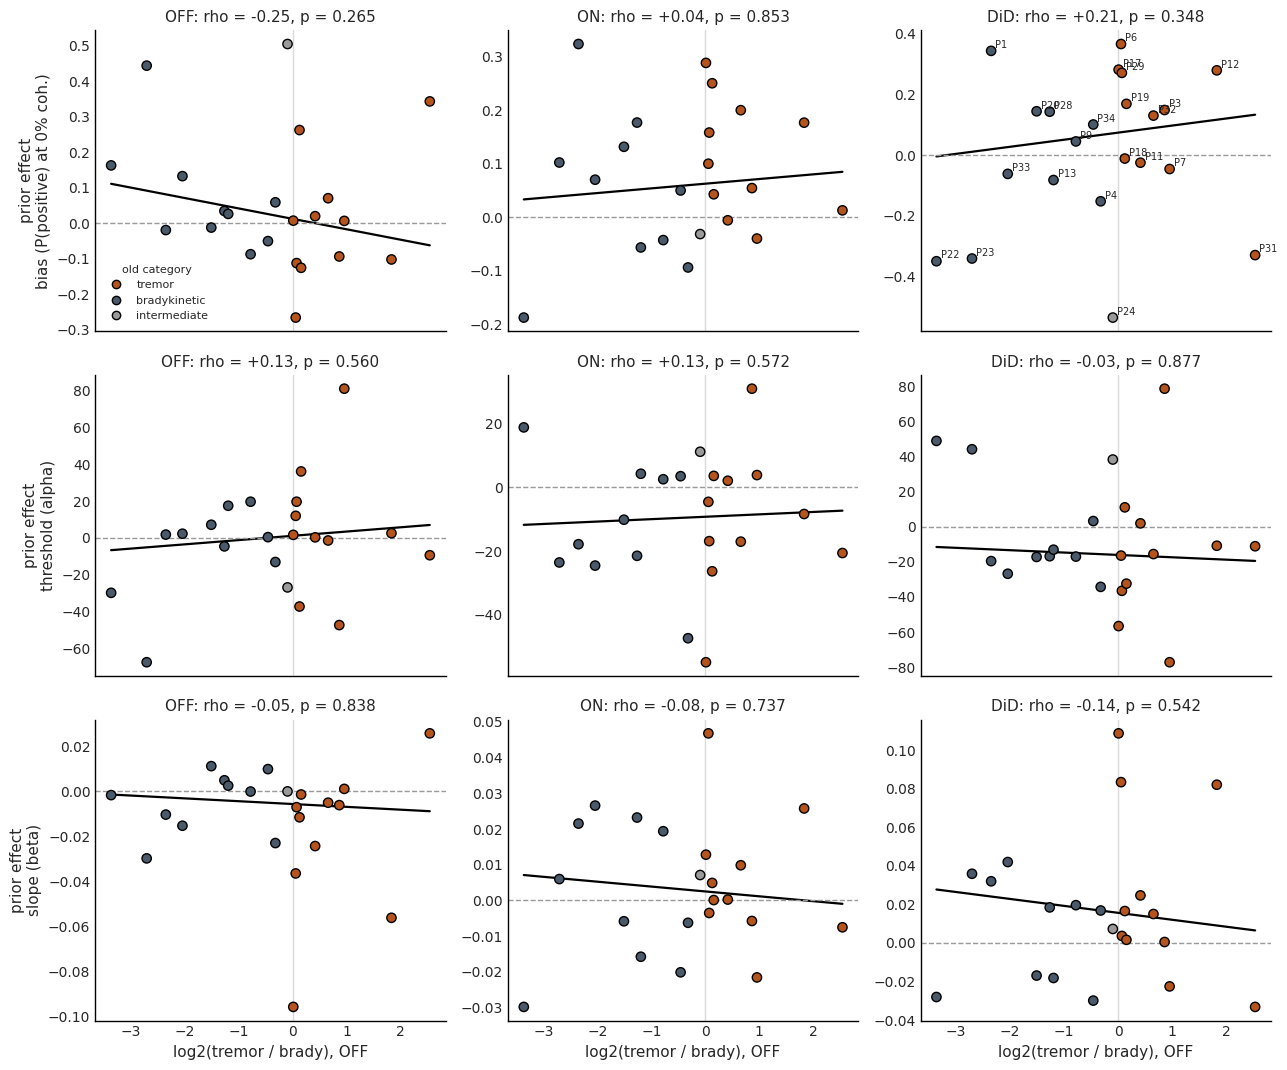

In [5]:
fig, axes = plt.subplots(len(PARAMS), 3, figsize=(13, 3.6 * len(PARAMS)), sharex=True)
for i, param in enumerate(PARAMS):
    for j, state in enumerate(["OFF", "ON", "DiD"]):
        ax = axes[i, j]
        y = prior_effects[f"{param} {state}"]
        ax.scatter(scores[SCORE], y, c=scores["category"].map(CATEGORY_COLOR), s=45, edgecolor="k", zorder=3)
        slope, intercept, _, _ = stats.theilslopes(y, scores[SCORE])
        grid = np.linspace(scores[SCORE].min(), scores[SCORE].max(), 50)
        ax.plot(grid, intercept + slope * grid, color="k", lw=1.6)
        ax.axhline(0, color="0.6", ls="--", lw=1)
        ax.axvline(0, color="0.85", lw=1, zorder=0)
        r = correlations.loc[(param, state)]
        ax.set_title(f"{state}: rho = {r['spearman rho']:+.2f}, p = {r['p (perm, rho)']:.3f}", fontsize=11)
        if j == 0:
            ax.set_ylabel(f"prior effect\n{PARAMS[param]}", fontsize=11)
        if i == len(PARAMS) - 1:
            ax.set_xlabel("log2(tremor / brady), OFF", fontsize=11)
        ax.tick_params(labelsize=10)
        ax.spines[["top", "right"]].set_visible(False)
        if param == "bias" and state == "DiD":
            for participant, value in y.items():
                ax.annotate(participant, (scores.loc[participant, SCORE], value), xytext=(3, 2), textcoords="offset points", fontsize=7)

handles = [plt.Line2D([], [], ls="", marker="o", mec="k", color=c, label=k) for k, c in CATEGORY_COLOR.items()]
axes[0, 0].legend(handles=handles, frameon=False, fontsize=8, title="old category", title_fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "prior_effect_vs_score.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "prior_effect_vs_score.png", dpi=200, bbox_inches="tight")
plt.show()

## Which patients carry the primary correlation?

Spearman rho with each patient dropped in turn, most negative shift first. A correlation that one
patient can reverse is not one to report without that caveat.

In [6]:
influence = leave_one_out_rho(scores[SCORE], prior_effects["bias DiD"], scores.index)
print(f"full-sample rho = {correlations.loc[primary, 'spearman rho']:+.3f}; leave-one-out range {influence['rho'].min():+.3f} to {influence['rho'].max():+.3f}")
influence.round(3).T

full-sample rho = +0.209; leave-one-out range +0.104 to +0.327


dropped,P22,P23,P12,P33,P13,P3,P4,P19,P6,P24,P29,P17,P34,P9,P32,P18,P28,P20,P11,P7,P31,P1
rho,0.104,0.104,0.16,0.161,0.181,0.183,0.195,0.196,0.200,0.203,0.205,0.212,0.213,0.213,0.216,0.231,0.236,0.236,0.240,0.255,0.323,0.327
shift,-0.106,-0.106,-0.05,-0.048,-0.029,-0.026,-0.015,-0.013,-0.009,-0.007,-0.004,0.002,0.004,0.004,0.006,0.022,0.027,0.027,0.031,0.045,0.114,0.118


## Which component of the score carries it?

The score is a ratio, so a correlation with it can come from tremor, from bradykinesia, or from both.
Tremor and bradykinesia severity (OFF) are each correlated with the primary DiD. They are themselves
only weakly related across patients, so the two rows are close to separate questions.

In [7]:
component_rows = {column: correlate(scores[column], prior_effects["bias DiD"]) for column in ["tremor_score", "bradykinesia_score", SCORE]}
print(f"tremor vs bradykinesia score across patients: rho = {stats.spearmanr(scores['tremor_score'], scores['bradykinesia_score']).statistic:+.2f}")
pd.DataFrame(component_rows).T.round(3)

tremor vs bradykinesia score across patients: rho = +0.04


,n,spearman rho,rho 2.5%,rho 97.5%,"p (perm, rho)",pearson r,"p (perm, r)"
tremor_score,22.0,0.353,-0.120,0.704,0.109,0.320,0.147
bradykinesia_score,22.0,0.062,-0.362,0.513,0.786,0.082,0.718
log2_trem_by_brady,22.0,0.209,-0.305,0.604,0.348,0.165,0.468


## For comparison: the old categorical test on the same numbers

`notebooks/2.20` compared the DiD between the two subtypes with a Mann-Whitney U test (P24 excluded).
Recomputed here from the same per-patient values so the two approaches sit side by side.

In [8]:
did = prior_effects["bias DiD"]
tremor, brady = did[scores["category"] == "tremor"], did[scores["category"] == "bradykinetic"]
u = stats.mannwhitneyu(tremor, brady)
print(f"categorical: tremor DiD {tremor.mean():+.3f} (n={len(tremor)}) vs brady {brady.mean():+.3f} (n={len(brady)}), Mann-Whitney p = {u.pvalue:.3f}")
print(f"continuous:  Spearman rho = {correlations.loc[primary, 'spearman rho']:+.3f} (n={int(correlations.loc[primary, 'n'])}), permutation p = {correlations.loc[primary, 'p (perm, rho)']:.3f}")

categorical: tremor DiD +0.112 (n=11) vs brady -0.021 (n=10), Mann-Whitney p = 0.098
continuous:  Spearman rho = +0.209 (n=22), permutation p = 0.348


In [9]:
prior_effects.join(scores[[SCORE, "category"]]).to_csv(OUTPUT_DIR / "prior_effects_by_patient.csv")
correlations.to_csv(OUTPUT_DIR / "prior_effect_vs_score.csv")
print("wrote prior_effects_by_patient.csv, prior_effect_vs_score.csv and the figure to", OUTPUT_DIR.relative_to(OUTPUT_DIR.parents[1]))

wrote prior_effects_by_patient.csv, prior_effect_vs_score.csv and the figure to outputs/notebooks_2


## Results

Values are from this run; permutation and bootstrap use a fixed seed.

**Primary test: the medication effect on prior use does not detectably vary with tremor dominance.**
DiD of `bias` against the score: Spearman rho = +0.21, 95% bootstrap interval [-0.31, +0.60],
permutation p = 0.35 (Pearson r = +0.17, p = 0.47). The direction matches the categorical result, but
the correlation is weak.

**This is weaker than the categorical test on the same numbers** (tremor vs bradykinesia DiD,
Mann-Whitney p = 0.098). Two patients that the categorical analysis treated favourably are the reason:

- **P24**, the "intermediate" patient (ratio 0.93), had the most negative DiD of anyone (-0.54). The
  split excluded P24; a correlation cannot.
- **P31**, the most tremor-dominant patient (ratio 5.8), had one of the most negative DiDs (-0.33).
  In the split P31 was one of 11 tremor patients; on a continuous axis P31 is the extreme point, and
  the trend runs the wrong way there.

The largest positive DiDs (P6, P17, P29, P12) sit just above the ratio-1 cut-off. The categorical
contrast therefore partly reflects where the line happened to fall, not a gradient with tremor
dominance. That reading is post hoc and is not tested here.

**Robustness of the primary correlation.** Leave-one-out rho ranges from +0.10 (without P22 or P23)
to +0.33 (without P1 or P31). No single patient makes it convincing.

**Secondary tests.** No OFF, ON or DiD correlation for `bias`, threshold or slope approaches
significance (all Holm-corrected p = 1.0). OFF-medication prior use is, if anything, weaker in more
tremor-dominant patients (rho = -0.25, p = 0.27).

**Components.** The DiD tracks tremor severity (rho = +0.35, p = 0.11) more than bradykinesia severity
(rho = +0.06, p = 0.79). Both are in the direction of "more severe, larger increase", not of
"tremor relative to bradykinesia", which is what the ratio measures. Not significant, and not
corrected for the extra tests, so it is a lead for a larger sample rather than a finding.